# Fronteira de Pareto Separada: Proposta vs. (Literatura + Descritivas)

Em vez de uma única fronteira global (Proposta destacada contra uma nuvem com todo o
resto junto), este notebook calcula **duas fronteiras de Pareto independentes**, por
paradigma:

- **Fronteira A**: só os 8 índices da Proposta calculados (Cp, Cpk, Pp, Ppk, p, np, c, u),
  competindo só entre si. O artigo reporta seis deles (np e u ordenam os atributos como p e c).
- **Fronteira B**: Literatura (19 métodos) + Descritivas (Amplitude/$\sigma$, IQR/$\sigma$,
  Assimetria, Curtose -- **sem** as versões `_BaseCompleta`, que usam a base inteira em
  vez de só a classe de anomalia), competindo só entre si. Dentro da Fronteira B, cada
  ponto é rotulado como "Literatura" ou "Descritiva", para facilitar a leitura.

Isso responde a uma pergunta mais justa do que a fronteira global: **"o melhor que a
Proposta consegue sozinha é estatisticamente parecido com o melhor que o resto consegue
sozinho?"** -- em vez de competir ponto a ponto contra a nuvem inteira de uma vez.

Cada ranking entra na análise só pelos seus **dois cotovelos** -- o ponto Kneedle
(geométrico) e o ponto Estatístico (regra de 1 desvio-padrão), calculados com a mesma
lógica do notebook 5 -- e não pela curva inteira do Backward Elimination. Só esses
pontos correspondem a modelos de fato "selecionados" pela metodologia; os demais N
da curva nunca foram escolhidos como configuração final, então não fazem sentido
competindo na fronteira.

Ao final, compara os valores de Acurácia Balanceada das duas fronteiras com o teste de
Mann-Whitney (não pareado -- as duas fronteiras quase nunca têm o mesmo número de
pontos).

**Como usar**: copie este notebook para a mesma pasta onde estão os
`Modelos<Paradigma>_CV_Consolidado.xlsx` (saída do notebook 4) e rode todas as células,
em ordem.

**Leitura**: o caderno abre cada arquivo consolidado do caderno 4 (1 por paradigma, 1 aba por ranking) com `pd.read_excel(..., sheet_name=None)` e trata cada aba como uma curva.

### 1. Configurações e leitura de todos os arquivos de modelo

In [1]:
import os
import re
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from datetime import datetime

FOLDER_PATH = os.getcwd()
OUT_DIR = os.path.join(FOLDER_PATH, "Resultados_DuplaFronteira")
os.makedirs(OUT_DIR, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

ORDEM_PARADIGMAS = ["DT", "RF", "GB", "SVM", "MLP", "GNB", "LogReg_Lasso"]

print(f"Diretório base: {FOLDER_PATH}")
print(f"Salvando resultados em: {OUT_DIR}")


def extrair_paradigma(filename):
    '''Modelos<Paradigma>_CV_Consolidado.xlsx -> <Paradigma> (ex.: LogReg_Lasso) --
    não-guloso até o primeiro _CV_, para funcionar mesmo com underscore no nome do
    paradigma.'''
    m = re.match(r"^Modelos(.+?)_CV_", filename)
    return m.group(1) if m else "Desconhecido"


REGEX_CEQ = re.compile(r"^(Cp|Cpk|Pp|Ppk|p|np|c|u)_(Original|Normalizado)$")
PREFIXOS_DESCRITIVAS = ("AmplitudeSigma", "IQRSigma", "Assimetria", "Curtose")


def classificar_grupo(nome_ranking):
    '''Classifica um ranking em "Proposta", "Descritiva" ou "Literatura".
    Retorna None para as versões "_BaseCompleta" das descritivas -- excluídas da
    análise por não serem pareadas com a mesma população (classe de anomalia) que
    todo o resto usa. Espera nome_ranking já sem o prefixo "Ranking_" (ex.:
    "Cp_Original", não "Ranking_Cp_Original") -- ver a limpeza feita no loop de
    leitura abaixo.'''
    if "BaseCompleta" in nome_ranking:
        return None
    if REGEX_CEQ.match(nome_ranking):
        return "Proposta"
    if nome_ranking.startswith(PREFIXOS_DESCRITIVAS):
        return "Descritiva"
    return "Literatura"


# --- Cotovelos: mesma lógica do notebook 5 (Kneedle geométrico + 1 desvio-padrão) ---
COL_X = "Nº de Atributos"
COL_Y = "Acurácia Balanceada Média"
COL_STD = "Acurácia Balanceada Desvio"


def get_kneedle_idx(df_sorted):
    '''Ponto de maior distância perpendicular à reta que liga o primeiro e o
    último ponto da curva (normalizada em [0,1] nos dois eixos). Produto
    vetorial 2D calculado manualmente (ax*by - ay*bx), não via np.cross, que a
    partir do NumPy 2.4 passou a exigir vetores 3D.'''
    x = df_sorted[COL_X].values.astype(float)
    y = df_sorted[COL_Y].values.astype(float)
    if x.max() == x.min() or y.max() == y.min() or len(x) < 3:
        return df_sorted.index[0]
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    coords = np.vstack((x_norm, y_norm)).T
    vec_line = coords[-1] - coords[0]
    vec_points = coords - coords[0]
    norm = np.linalg.norm(vec_line)
    if norm == 0:
        return df_sorted.index[0]
    distances = (vec_line[0] * vec_points[:, 1] - vec_line[1] * vec_points[:, 0]) / norm
    return df_sorted.index[np.argmax(np.abs(distances))]


def get_estatistico_idx(df_sorted):
    '''Regra de 1 desvio-padrão: entre os pontos cuja acurácia fica a até 1
    desvio-padrão da melhor acurácia da curva, escolhe o de menor N (modelo
    mais simples estatisticamente indistinguível do melhor).'''
    idx_melhor = df_sorted[COL_Y].idxmax()
    melhor_acc = df_sorted.loc[idx_melhor, COL_Y]
    desvio = df_sorted.loc[idx_melhor, COL_STD] if COL_STD in df_sorted.columns and pd.notna(df_sorted.loc[idx_melhor, COL_STD]) else 0.0
    limiar = melhor_acc - desvio
    candidatos = df_sorted[df_sorted[COL_Y] >= limiar]
    return candidatos[COL_X].idxmin()


# Procura os arquivos consolidados (1 por paradigma), não mais 1 arquivo por ranking
arquivos_consolidados = sorted([
    f for f in os.listdir(FOLDER_PATH)
    if f.startswith("Modelos") and f.endswith("_CV_Consolidado.xlsx")
])
print(f"\n{len(arquivos_consolidados)} arquivo(s) 'Modelos<Paradigma>_CV_Consolidado.xlsx' encontrado(s).")

registros = []
for arquivo in arquivos_consolidados:
    paradigma = extrair_paradigma(arquivo)

    try:
        # Sheet_name=None lê TODAS as abas de uma vez, devolvendo {nome_da_aba: DataFrame} -- cada aba é um ranking
        todas_as_abas = pd.read_excel(os.path.join(FOLDER_PATH, arquivo), sheet_name=None)
    except Exception as e:
        print(f"Erro ao ler {arquivo}: {e}")
        continue

    for nome_aba, df in todas_as_abas.items():
        # O nome da aba é o nome do ranking (ex.: "Ranking_Cp_Original") -- remove o
        # prefixo "Ranking_" para casar com classificar_grupo(), que espera o nome
        # "nu" (ex.: "Cp_Original"), igual ao comportamento de antes da consolidação.
        nome_ranking = nome_aba[len("Ranking_"):] if nome_aba.startswith("Ranking_") else nome_aba

        grupo = classificar_grupo(nome_ranking)
        if grupo is None:
            continue  # _BaseCompleta -- fora da análise

        if COL_X not in df.columns or COL_Y not in df.columns:
            continue

        df_sorted = df.sort_values(COL_X, ascending=True).reset_index(drop=True)
        if len(df_sorted) < 2:
            continue

        # Só os 2 cotovelos (Kneedle + Estatístico), não a curva inteira
        idx_kneedle = get_kneedle_idx(df_sorted)
        idx_estatistico = get_estatistico_idx(df_sorted)

        for tipo, idx in [("Kneedle", idx_kneedle), ("Estatístico", idx_estatistico)]:
            linha = df_sorted.loc[idx]
            registros.append({
                COL_X: linha[COL_X], COL_Y: linha[COL_Y],
                "Paradigma": paradigma, "Ranking": nome_ranking, "Grupo": grupo, "Tipo": tipo,
            })

df_all = pd.DataFrame(registros).drop_duplicates(subset=["Paradigma", "Ranking", "Tipo"]) if registros else pd.DataFrame()
print(f"{len(df_all)} cotovelos (Paradigma x Ranking x Tipo) carregados -- 2 por ranking (Kneedle + Estatístico).")
print(df_all["Grupo"].value_counts())
print(df_all["Tipo"].value_counts())


Diretório base: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo
Salvando resultados em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_DuplaFronteira

7 arquivo(s) 'Modelos<Paradigma>_CV_Consolidado.xlsx' encontrado(s).
✅ 560 cotovelos (Paradigma x Ranking x Tipo) carregados -- 2 por ranking (Kneedle + Estatístico).
Grupo
Literatura    266
Proposta      224
Descritiva     70
Name: count, dtype: int64
Tipo
Kneedle        280
Estatístico    280
Name: count, dtype: int64


### 2. Função da fronteira de Pareto (staircase: menor N, maior acurácia)

In [2]:
def get_pareto_frontier(df, col_x="Nº de Atributos", col_y="Acurácia Balanceada Média"):
    """Fronteira de Pareto para minimizar N e maximizar Acurácia: ordena por N
    crescente e mantém só os pontos cuja acurácia supera tudo que veio antes."""
    df_sorted = df.sort_values(col_x, ascending=True).reset_index(drop=True)
    pareto_idx = []
    melhor_acc = -np.inf
    for i, row in df_sorted.iterrows():
        if row[col_y] > melhor_acc:
            pareto_idx.append(i)
            melhor_acc = row[col_y]
    return df_sorted.loc[pareto_idx].reset_index(drop=True)

### 3. Gráficos e tabelas por paradigma

Para cada paradigma: duas fronteiras (Proposta sozinha; Literatura+Descritiva juntas),
dois gráficos, e os pontos que caem exatamente sobre cada fronteira são listados numa
tabela por paradigma (mesmo estilo da Tabela 4.15 -- Abordagem, Método, Custo
Dimensional, Desempenho, intercalados por custo crescente).


==================== DT ====================


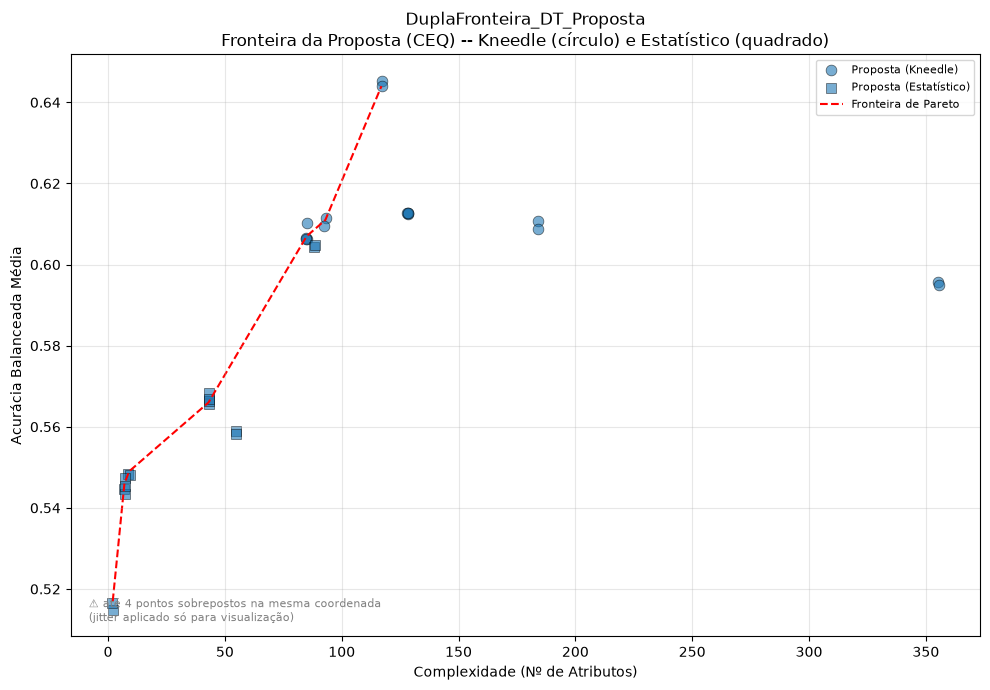

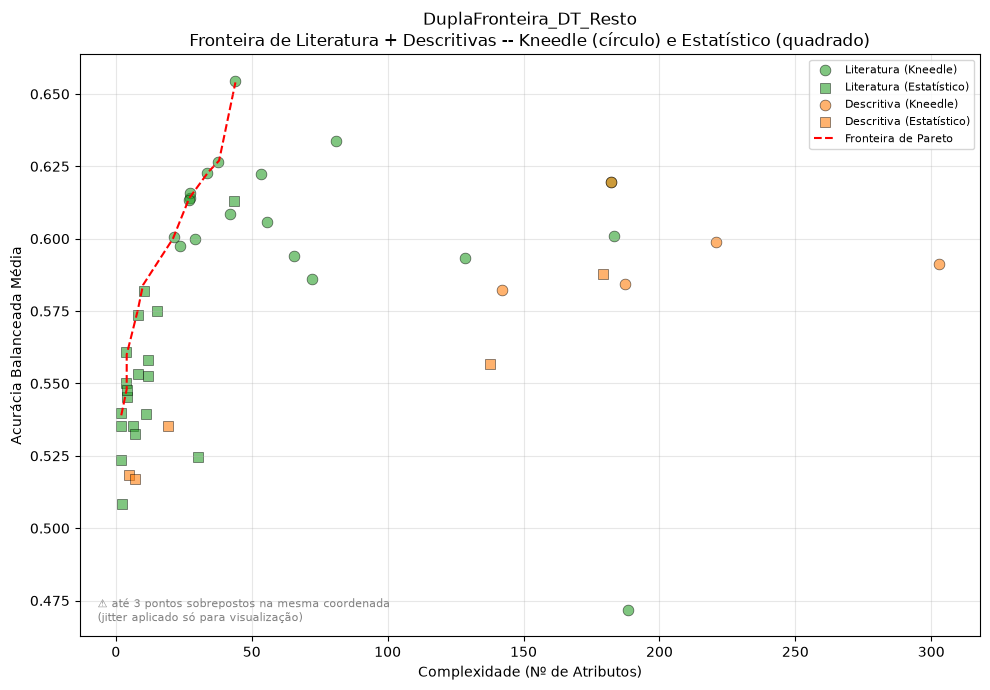

🖼️  DuplaFronteira_DT_Proposta_20261023_124943.png
🖼️  DuplaFronteira_DT_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_DT_Proposta_20261023_124943.xlsx -- 7 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_DT_Resto_20261023_124943.xlsx -- 10 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_DT_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_DT_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 6 sobreposto(s)
Pontos na fronteira -- Proposta: 7 | Literatura+Descritiva: 10
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.4747

==================== RF ====================


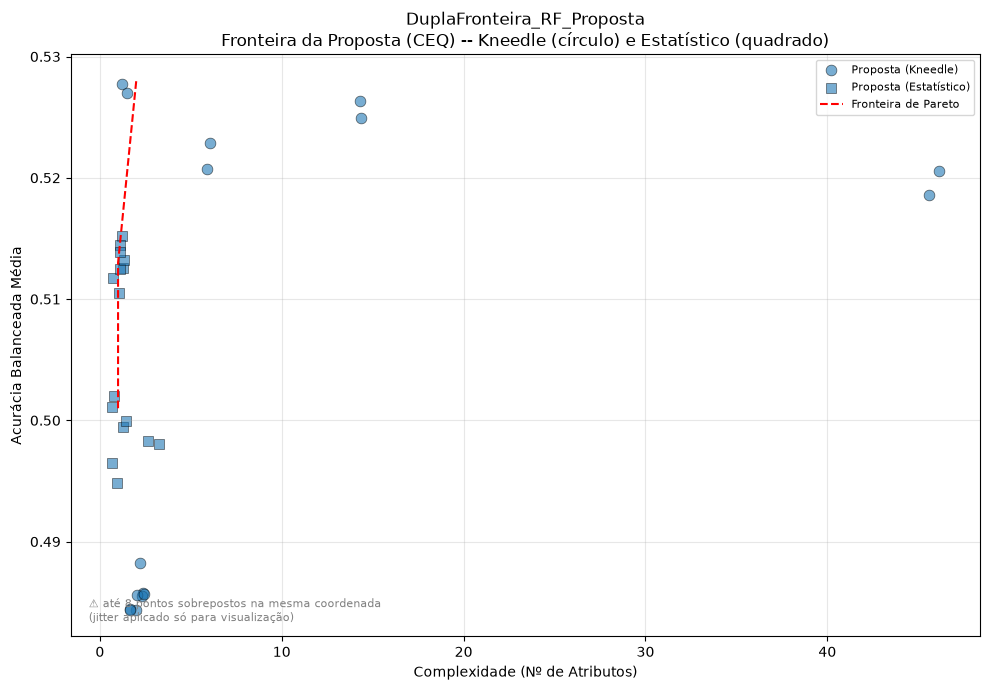

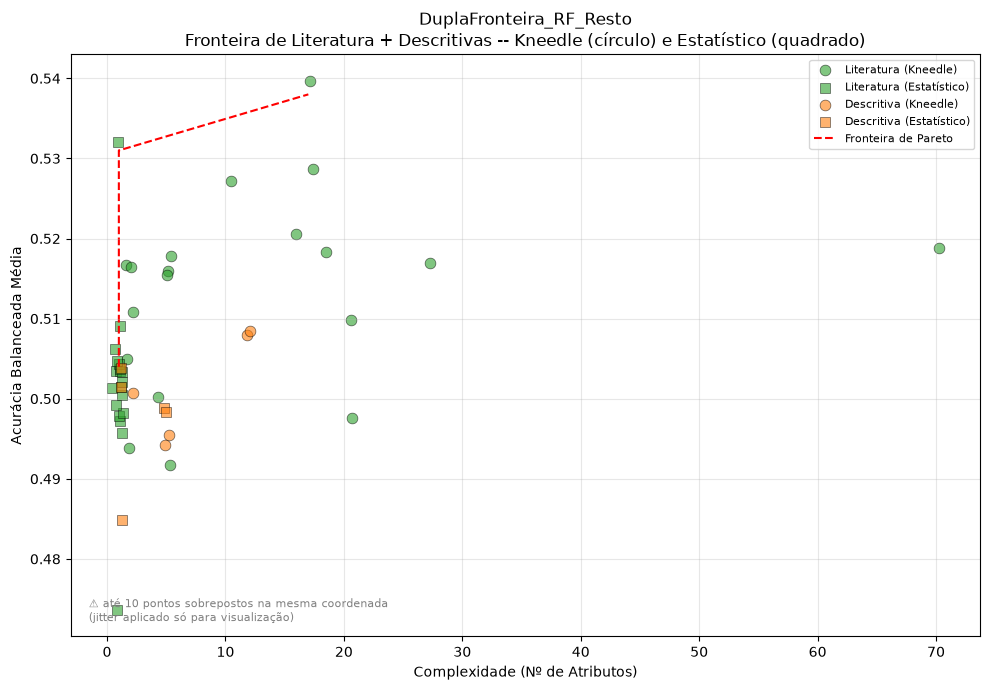

🖼️  DuplaFronteira_RF_Proposta_20261023_124943.png
🖼️  DuplaFronteira_RF_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_RF_Proposta_20261023_124943.xlsx -- 3 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_RF_Resto_20261023_124943.xlsx -- 5 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_RF_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_RF_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 29 sobreposto(s)
Pontos na fronteira -- Proposta: 3 | Literatura+Descritiva: 5
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.6286

==================== GB ====================


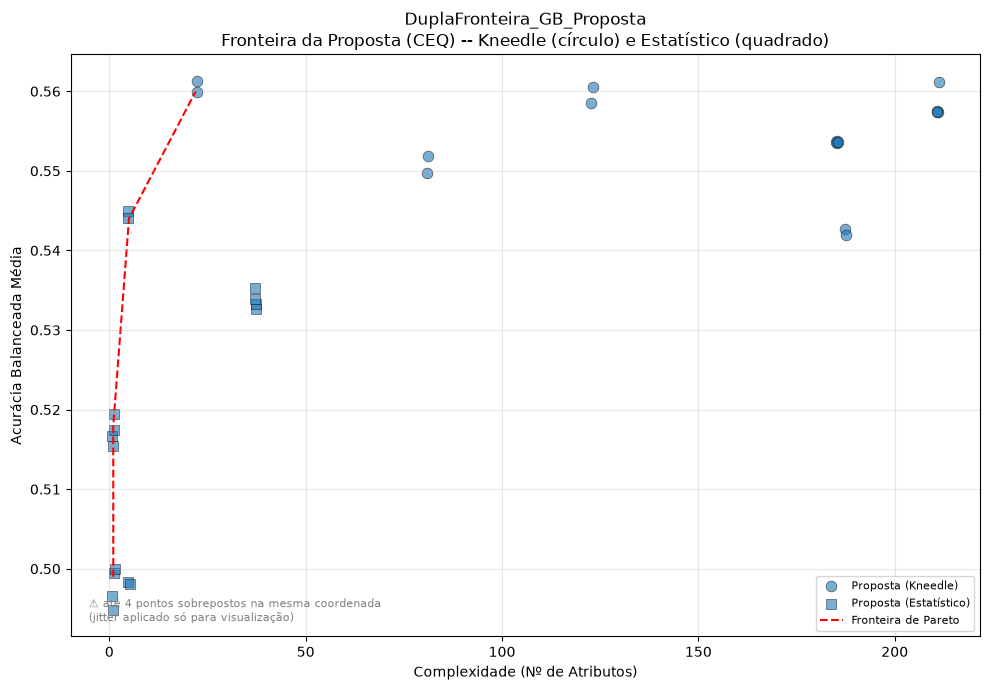

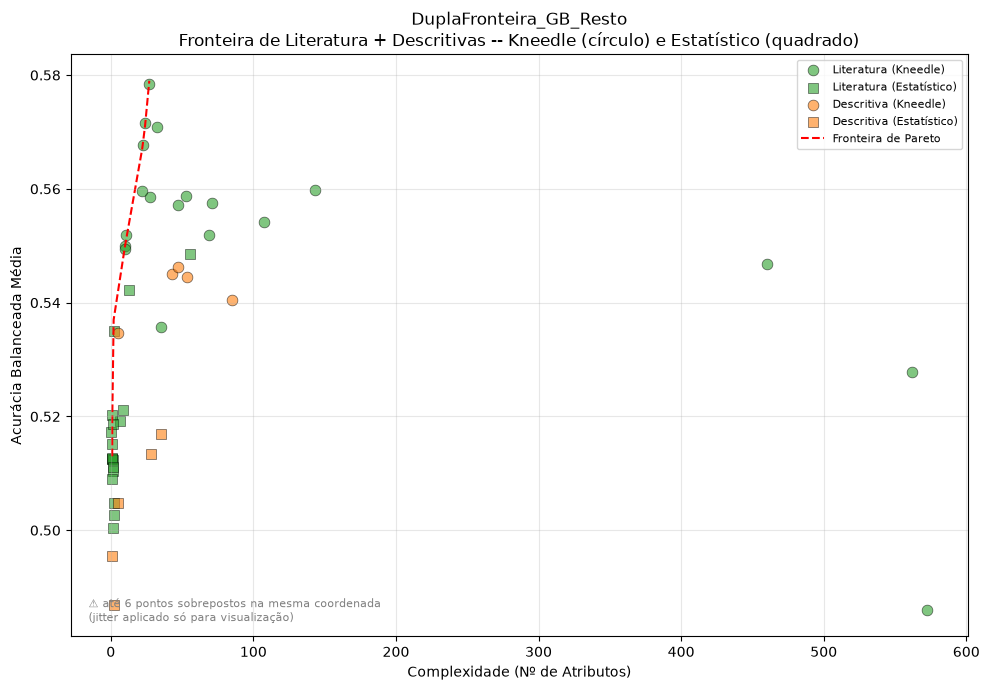

🖼️  DuplaFronteira_GB_Proposta_20261023_124943.png
🖼️  DuplaFronteira_GB_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_GB_Proposta_20261023_124943.xlsx -- 4 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_GB_Resto_20261023_124943.xlsx -- 7 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_GB_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_GB_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 13 sobreposto(s)
Pontos na fronteira -- Proposta: 4 | Literatura+Descritiva: 7
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.3152

==================== SVM ====================


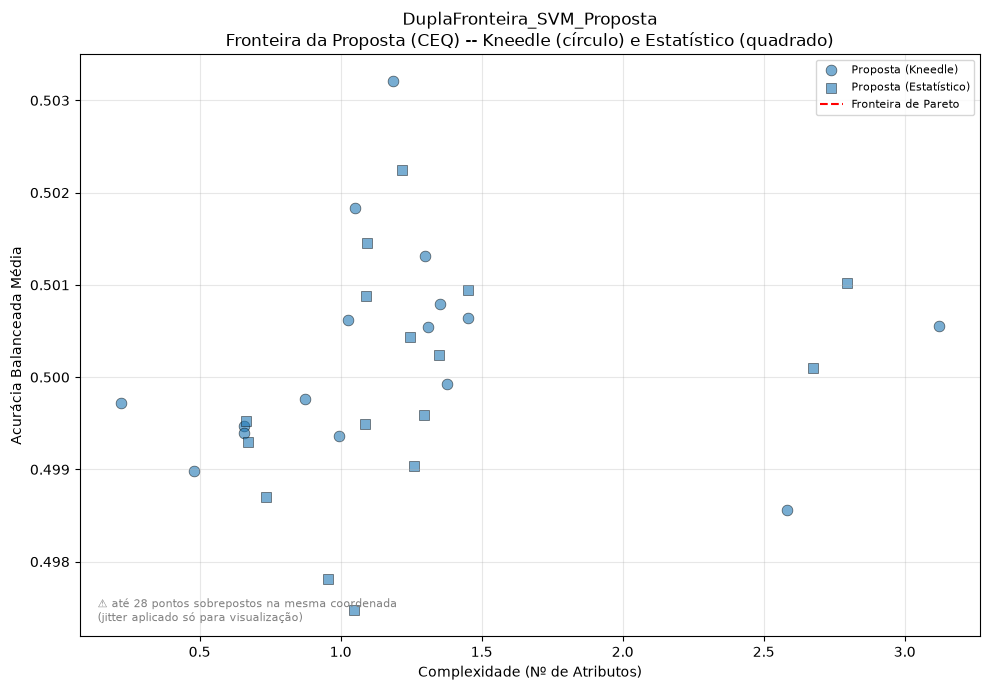

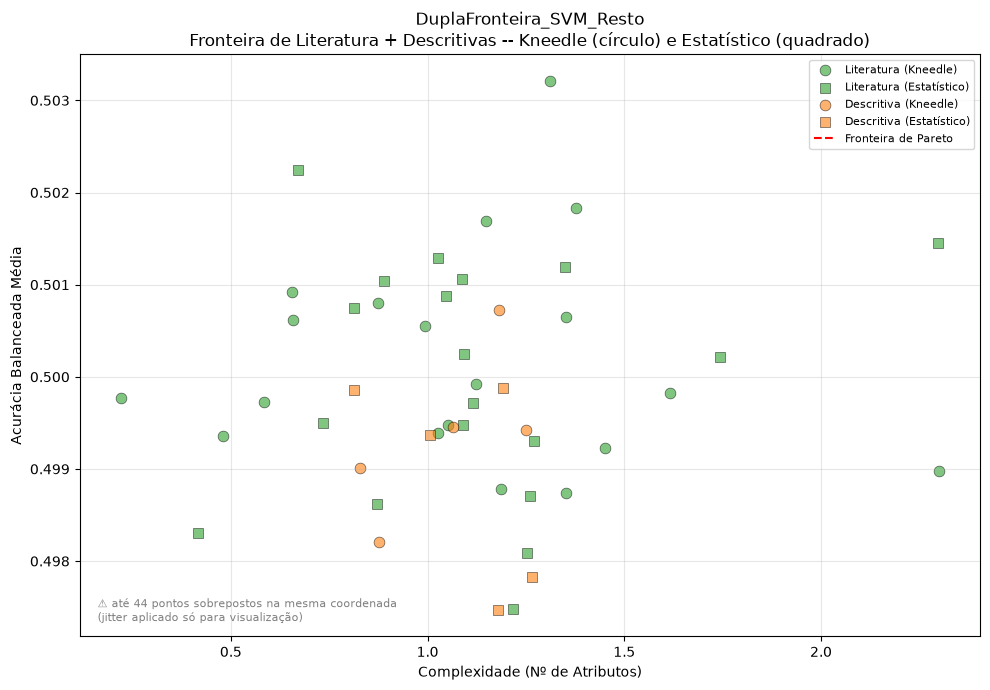

🖼️  DuplaFronteira_SVM_Proposta_20261023_124943.png
🖼️  DuplaFronteira_SVM_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_SVM_Proposta_20261023_124943.xlsx -- 1 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_SVM_Resto_20261023_124943.xlsx -- 2 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_SVM_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_SVM_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 48 sobreposto(s)
Pontos na fronteira -- Proposta: 1 | Literatura+Descritiva: 2
Mann-Whitney: não computável (pontos insuficientes)

==================== MLP ====================


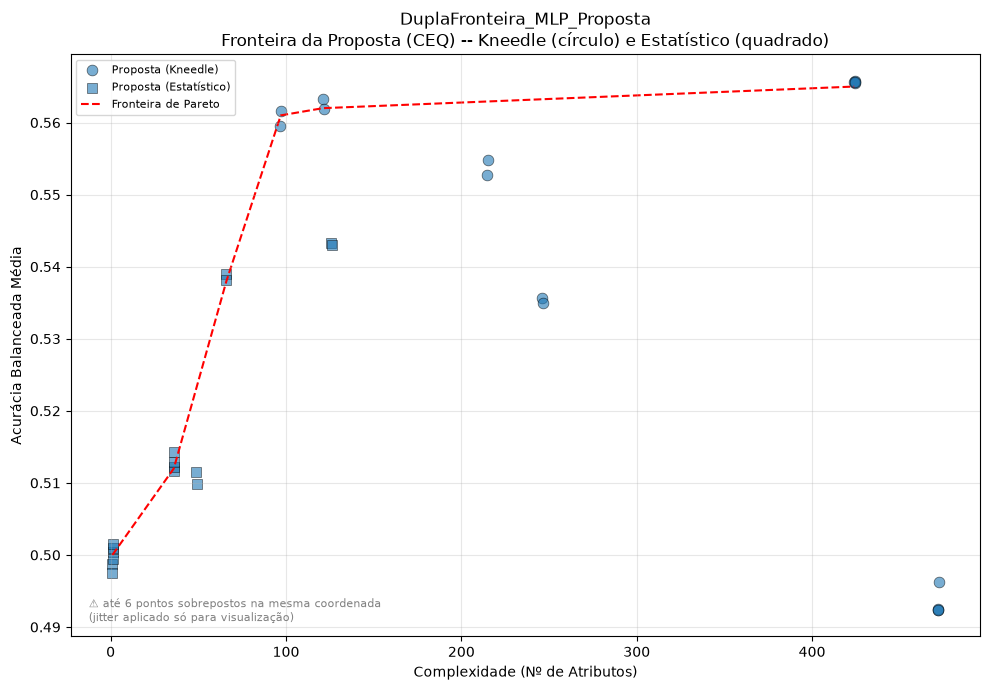

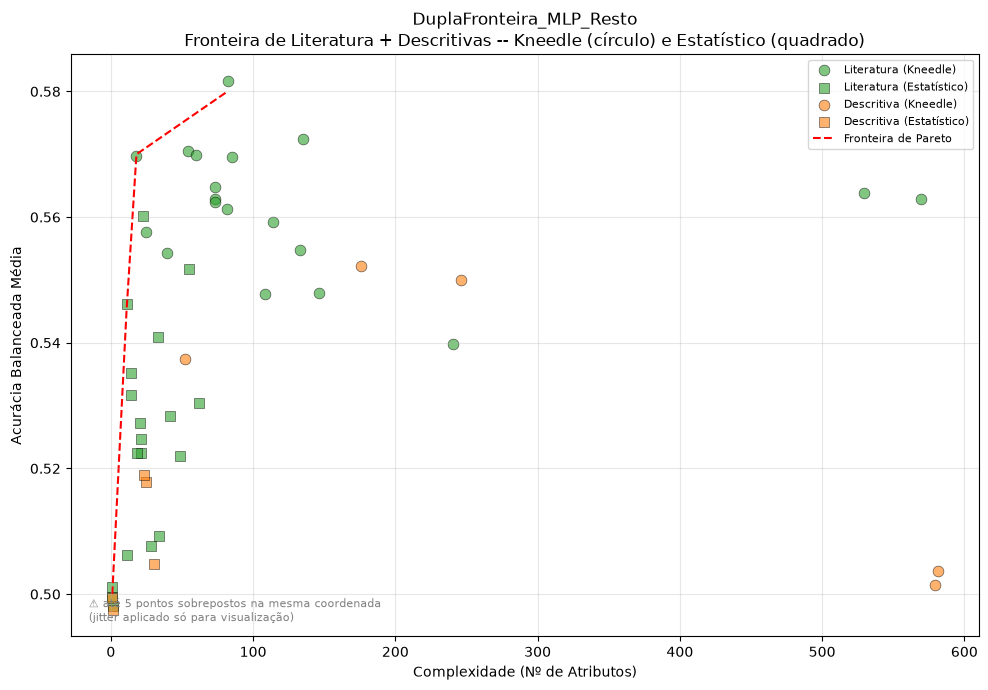

🖼️  DuplaFronteira_MLP_Proposta_20261023_124943.png
🖼️  DuplaFronteira_MLP_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_MLP_Proposta_20261023_124943.xlsx -- 6 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_MLP_Resto_20261023_124943.xlsx -- 5 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_MLP_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_MLP_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 11 sobreposto(s)
Pontos na fronteira -- Proposta: 6 | Literatura+Descritiva: 5
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.5212

==================== GNB ====================


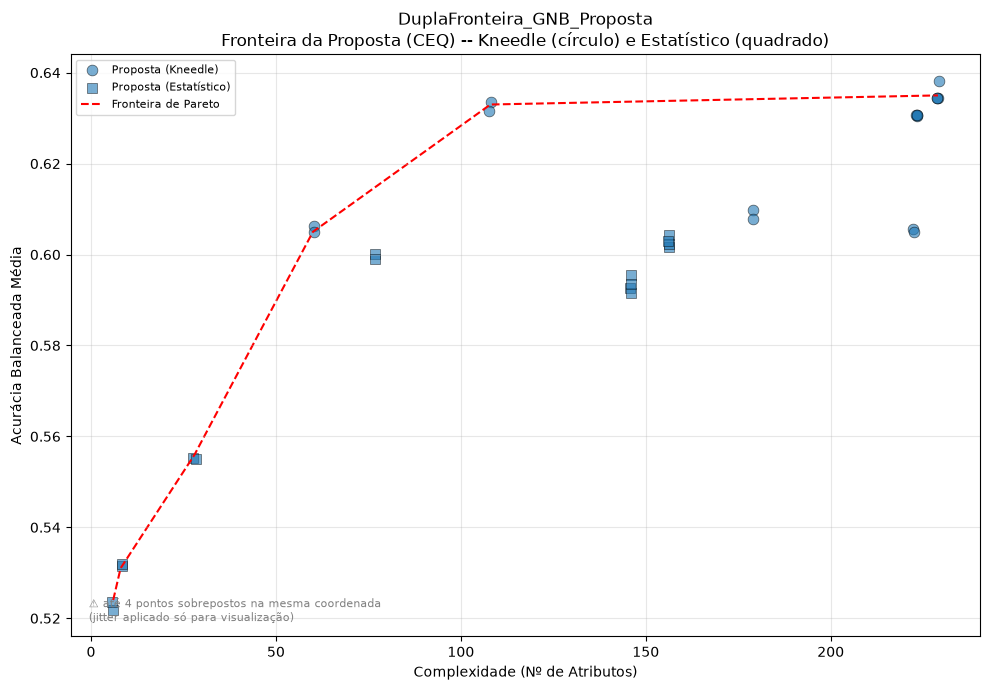

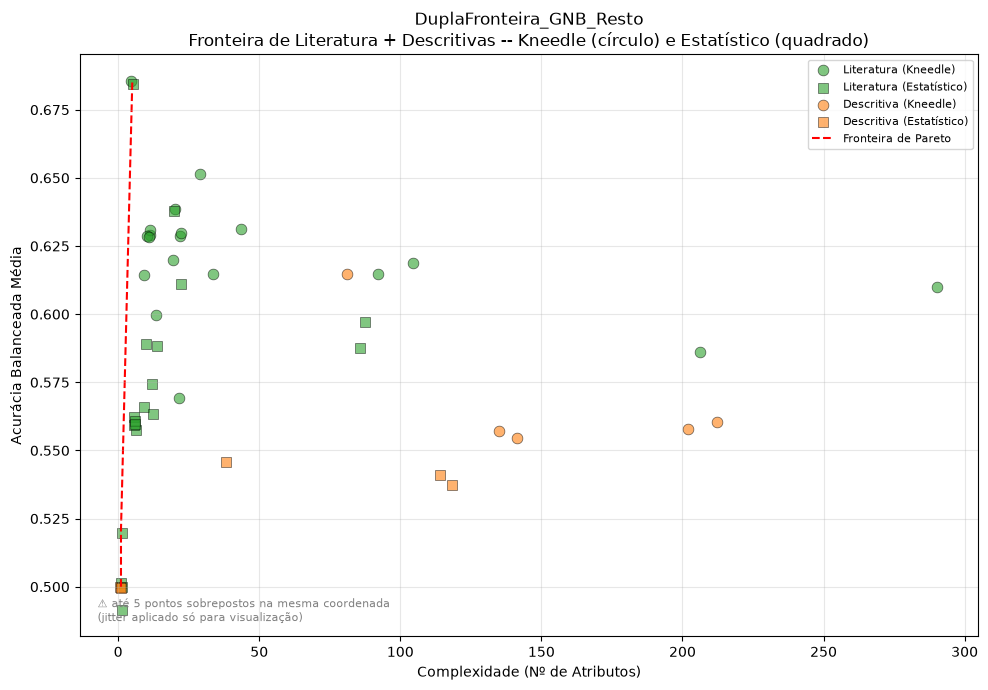

🖼️  DuplaFronteira_GNB_Proposta_20261023_124943.png
🖼️  DuplaFronteira_GNB_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_GNB_Proposta_20261023_124943.xlsx -- 6 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_GNB_Resto_20261023_124943.xlsx -- 4 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_GNB_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_GNB_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 16 sobreposto(s)
Pontos na fronteira -- Proposta: 6 | Literatura+Descritiva: 4
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.5476

==================== LogReg_Lasso ====================


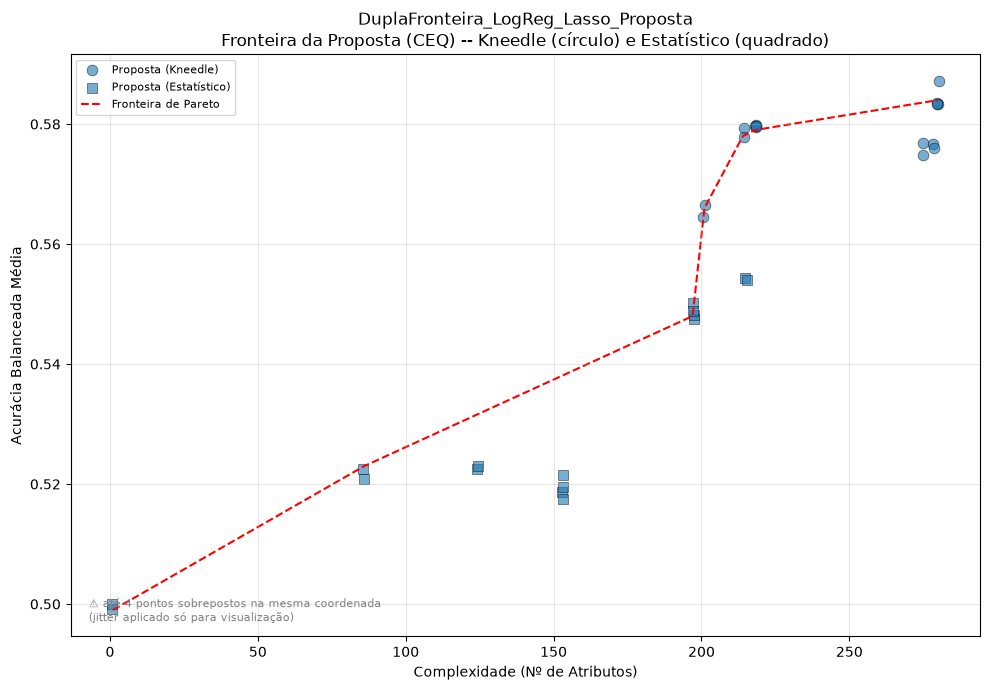

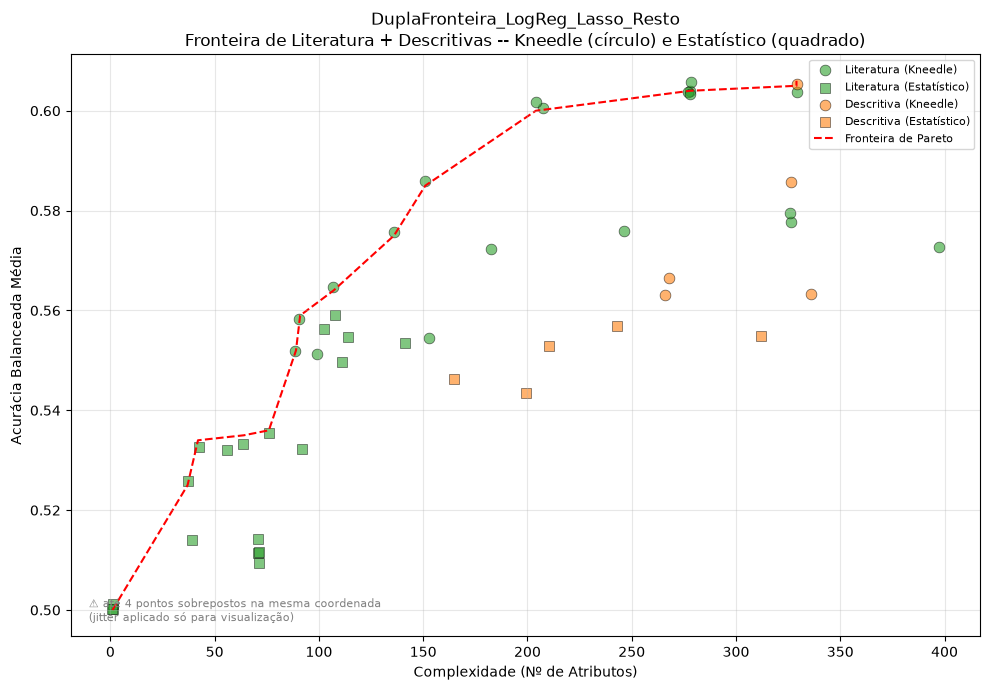

🖼️  DuplaFronteira_LogReg_Lasso_Proposta_20261023_124943.png
🖼️  DuplaFronteira_LogReg_Lasso_Resto_20261023_124943.png
📊 DuplaFronteira_Tabela_LogReg_Lasso_Proposta_20261023_124943.xlsx -- 7 ponto(s) na fronteira
📊 DuplaFronteira_Tabela_LogReg_Lasso_Resto_20261023_124943.xlsx -- 14 ponto(s) na fronteira
📋 DuplaFronteira_TodosPontos_LogReg_Lasso_Proposta_20261023_124943.xlsx -- 32 ponto(s) total(is), 32 sobreposto(s)
📋 DuplaFronteira_TodosPontos_LogReg_Lasso_Resto_20261023_124943.xlsx -- 48 ponto(s) total(is), 11 sobreposto(s)
Pontos na fronteira -- Proposta: 7 | Literatura+Descritiva: 14
Mann-Whitney (Proposta x Resto, fronteiras): p = 0.5846

✅ Comparação final salva em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_DuplaFronteira\DuplaFronteira_Comparacao_PropostaVsResto_20261023_124943.xlsx
   Paradigma  N Pontos Fronteira Proposta  N Pontos Fronteira Resto  Média Acc Proposta  Média Acc Resto  p-valor (Mann-Whitney)  Diferença Significativa (p<=0.05)
         

In [3]:
COR_GRUPO = {"Proposta": "#1f77b4", "Literatura": "#2ca02c", "Descritiva": "#ff7f0e"}
MARCADOR_TIPO = {"Kneedle": "o", "Estatístico": "s"}


def plot_fronteira(df_grupo, titulo, caminho_arquivo, cores_por_subgrupo=None):
    fig, ax = plt.subplots(figsize=(10, 7))

    if cores_por_subgrupo:
        grupos_cor = cores_por_subgrupo
    else:
        grupos_cor = {"Proposta": COR_GRUPO["Proposta"]}

    # Conta quantos pontos caem exatamente na mesma coordenada (Dim, Acc) -- usado
    # para o jitter visual abaixo e para o aviso de sobreposição no título.
    chave = df_grupo["Nº de Atributos"].astype(str) + "_" + df_grupo["Acurácia Balanceada Média"].round(4).astype(str)
    contagem_sobreposicao = chave.value_counts()
    n_max_sobreposto = int(contagem_sobreposicao.max()) if len(contagem_sobreposicao) else 1

    rng_jitter = np.random.default_rng(42)
    for subgrupo, cor in grupos_cor.items():
        for tipo, marcador in MARCADOR_TIPO.items():
            sub = df_grupo[(df_grupo["Grupo"] == subgrupo) & (df_grupo["Tipo"] == tipo)]
            if sub.empty:
                continue
            # Jitter pequeno e só visual (não altera o cálculo da fronteira, que usa
            # df_grupo original) -- evita que pontos sobrepostos pareçam "1 ponto só"
            jitter_x = rng_jitter.normal(0, 0.4, size=len(sub))
            jitter_y = rng_jitter.normal(0, 0.0015, size=len(sub))
            ax.scatter(sub["Nº de Atributos"] + jitter_x, sub["Acurácia Balanceada Média"] + jitter_y,
                       c=cor, s=60, alpha=0.6, edgecolors="black", linewidths=0.5,
                       marker=marcador, label=f"{subgrupo} ({tipo})")

    if n_max_sobreposto > 1:
        ax.text(0.02, 0.02, f"até {n_max_sobreposto} pontos sobrepostos na mesma coordenada\n(jitter aplicado só para visualização)",
                transform=ax.transAxes, fontsize=8, color="gray", va="bottom")

    pareto = get_pareto_frontier(df_grupo)
    ax.plot(pareto["Nº de Atributos"], pareto["Acurácia Balanceada Média"],
            "r--", linewidth=1.5, label="Fronteira de Pareto", zorder=1)

    ax.set_xlabel("Complexidade (Nº de Atributos)")
    ax.set_ylabel("Acurácia Balanceada Média")
    ax.set_title(titulo)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(caminho_arquivo, dpi=150)
    plt.show()
    plt.close()
    return pareto


def tabela_pontos_na_fronteira(df_grupo_completo):
    """Entre os cotovelos (Kneedle + Estatístico) do grupo, identifica quais caem
    exatamente sobre a fronteira de Pareto e monta a tabela de síntese."""
    pareto = get_pareto_frontier(df_grupo_completo)
    pareto_tuplas = list(zip(pareto["Nº de Atributos"].values, pareto["Acurácia Balanceada Média"].values))

    registros = []
    for _, row in df_grupo_completo.iterrows():
        esta_na_fronteira = any(
            np.isclose(row["Nº de Atributos"], px, atol=1e-6) and
            np.isclose(row["Acurácia Balanceada Média"], py, atol=1e-6)
            for px, py in pareto_tuplas
        )
        if esta_na_fronteira:
            registros.append({
                "Grupo": row["Grupo"], "Método": f"{row['Ranking']} ({row['Tipo']})",
                "Dim": int(row["Nº de Atributos"]), "Acc": float(row["Acurácia Balanceada Média"]),
            })
    df_r = pd.DataFrame(registros).drop_duplicates()
    if df_r.empty:
        return df_r
    agrupado = df_r.groupby(["Grupo", "Dim", "Acc"])["Método"].apply(list).reset_index()

    def fmt_metodos(lista):
        if len(lista) == 1: return lista[0]
        if len(lista) <= 2: return ", ".join(lista)
        return f"{lista[0]}, {lista[1]} (+{len(lista)-2} empatados)"

    agrupado["Metodo_fmt"] = agrupado["Método"].apply(fmt_metodos)
    agrupado = agrupado.sort_values(["Dim", "Acc"]).reset_index(drop=True)
    return agrupado[["Grupo", "Metodo_fmt", "Dim", "Acc"]]


resultados_comparacao = []

for paradigma in ORDEM_PARADIGMAS:
    df_p = df_all[df_all["Paradigma"] == paradigma]
    if df_p.empty:
        continue

    df_proposta = df_p[df_p["Grupo"] == "Proposta"]
    df_resto = df_p[df_p["Grupo"].isin(["Literatura", "Descritiva"])]

    if df_proposta.empty or df_resto.empty:
        print(f"{paradigma}: faltam dados de um dos dois grupos. Pulando.")
        continue

    print(f"\n{'='*20} {paradigma} {'='*20}")

    # Nome-base de cada grupo -- usado IDÊNTICO no título do gráfico, no nome de
    # todo arquivo salvo e em todo print do console, para nunca precisar adivinhar
    # qual print corresponde a qual arquivo.
    nome_a = f"{paradigma}_Proposta"
    nome_b = f"{paradigma}_Resto"

    caminho_a = os.path.join(OUT_DIR, f"DuplaFronteira_{nome_a}_{timestamp}.png")
    pareto_a = plot_fronteira(df_proposta, f"DuplaFronteira_{nome_a}\nFronteira da Proposta (CEQ) -- Kneedle (círculo) e Estatístico (quadrado)", caminho_a)

    caminho_b = os.path.join(OUT_DIR, f"DuplaFronteira_{nome_b}_{timestamp}.png")
    pareto_b = plot_fronteira(df_resto, f"DuplaFronteira_{nome_b}\nFronteira de Literatura + Descritivas -- Kneedle (círculo) e Estatístico (quadrado)",
                               caminho_b, cores_por_subgrupo={"Literatura": COR_GRUPO["Literatura"], "Descritiva": COR_GRUPO["Descritiva"]})
    print(f"🖼️  DuplaFronteira_{nome_a}_{timestamp}.png")
    print(f"🖼️  DuplaFronteira_{nome_b}_{timestamp}.png")

    tab_a = tabela_pontos_na_fronteira(df_proposta)
    tab_b = tabela_pontos_na_fronteira(df_resto)

    if not tab_a.empty:
        arq_tab_a = f"DuplaFronteira_Tabela_{nome_a}_{timestamp}.xlsx"
        tab_a.to_excel(os.path.join(OUT_DIR, arq_tab_a), index=False)
        print(f"{arq_tab_a} -- {len(tab_a)} ponto(s) na fronteira")
    if not tab_b.empty:
        arq_tab_b = f"DuplaFronteira_Tabela_{nome_b}_{timestamp}.xlsx"
        tab_b.to_excel(os.path.join(OUT_DIR, arq_tab_b), index=False)
        print(f"{arq_tab_b} -- {len(tab_b)} ponto(s) na fronteira")

    # <<< Exporta TODOS os pontos (não só os que caem na fronteira), um Excel por
    # grupo/paradigma -- para conferir manualmente se pontos estão sobrepostos
    # (mesma coordenada Dim/Acc) e não "faltando". Marca Sobreposto=True quando
    # outro ponto do mesmo grupo cai na mesma coordenada (arredondada).
    def exportar_todos_os_pontos(df_grupo, caminho):
        df_exp = df_grupo[["Grupo", "Ranking", "Tipo", "Nº de Atributos", "Acurácia Balanceada Média"]].copy()
        df_exp = df_exp.rename(columns={"Nº de Atributos": "Dim", "Acurácia Balanceada Média": "Acc"})
        df_exp["Acc_arred"] = df_exp["Acc"].round(4)
        contagem = df_exp.groupby(["Dim", "Acc_arred"])["Ranking"].transform("count")
        df_exp["Sobreposto"] = contagem > 1
        df_exp["Qtd_no_mesmo_ponto"] = contagem
        df_exp = df_exp.drop(columns="Acc_arred").sort_values(["Dim", "Acc"]).reset_index(drop=True)
        df_exp.to_excel(caminho, index=False)
        return df_exp

    arq_todos_a = f"DuplaFronteira_TodosPontos_{nome_a}_{timestamp}.xlsx"
    arq_todos_b = f"DuplaFronteira_TodosPontos_{nome_b}_{timestamp}.xlsx"
    todos_a = exportar_todos_os_pontos(df_proposta, os.path.join(OUT_DIR, arq_todos_a))
    todos_b = exportar_todos_os_pontos(df_resto, os.path.join(OUT_DIR, arq_todos_b))
    print(f"{arq_todos_a} -- {len(todos_a)} ponto(s) total(is), {todos_a['Sobreposto'].sum()} sobreposto(s)")
    print(f"{arq_todos_b} -- {len(todos_b)} ponto(s) total(is), {todos_b['Sobreposto'].sum()} sobreposto(s)")

    print(f"Pontos na fronteira -- Proposta: {len(tab_a)} | Literatura+Descritiva: {len(tab_b)}")

    valores_a = pareto_a["Acurácia Balanceada Média"].values
    valores_b = pareto_b["Acurácia Balanceada Média"].values
    if len(valores_a) >= 1 and len(valores_b) >= 1 and not (len(valores_a) == 1 and len(valores_b) == 1):
        try:
            stat, p = mannwhitneyu(valores_a, valores_b, alternative="two-sided")
            sig = bool(p <= 0.05)
        except ValueError:
            p, sig = np.nan, False
    else:
        p, sig = np.nan, False

    resultados_comparacao.append({
        "Paradigma": paradigma,
        "N Pontos Fronteira Proposta": len(valores_a),
        "N Pontos Fronteira Resto": len(valores_b),
        "Média Acc Proposta": round(float(np.mean(valores_a)), 4),
        "Média Acc Resto": round(float(np.mean(valores_b)), 4),
        "p-valor (Mann-Whitney)": round(float(p), 4) if not pd.isna(p) else np.nan,
        "Diferença Significativa (p<=0.05)": sig,
    })
    print(f"Mann-Whitney (Proposta x Resto, fronteiras): p = {p:.4f}" if not pd.isna(p) else "Mann-Whitney: não computável (pontos insuficientes)")

df_comparacao = pd.DataFrame(resultados_comparacao)
caminho_comparacao = os.path.join(OUT_DIR, f"DuplaFronteira_Comparacao_PropostaVsResto_{timestamp}.xlsx")
df_comparacao.to_excel(caminho_comparacao, index=False)
print(f"\nComparação final salva em: {caminho_comparacao}")
print(df_comparacao.to_string(index=False))